In [93]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import random

In [167]:
class Value:
    def __init__(self, data, _children = (), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda: None
 
    def __repr__(self):
        return f"Value(data = {self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
    
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        
        out._backward = _backward


        return out

    def __rmul__(self, other):
        return self * other

    def tanh(self):
        
        n = self.data
        t = (math.exp(2*n) - 1)/(math.exp(2*n)+1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1-t**2) * out.grad
            
        out._backward = _backward

        return out


    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * (other**(-1))
    
    def __pow__(self, expon):
        assert isinstance(expon, (int, float))
        x = self.data
        out = Value(x**expon, (self, ), f'**{expon}')

        def _backward():
            self.grad += (expon) * (x**(expon-1)) * out.grad
                    
        out._backward = _backward

        return out

    def __sub__(self, other):
        return self + other *-1

    def __radd__(self, other):   # other + self
        return self + other
    def __rsub__(self, other):   # other + self
            return self + other *-1
    
    def backward(self):
        self.grad = 1.0
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        for node in reversed(topo):
            node._backward()


In [123]:
a = Value(2.0)
b = Value(4.0)

print(a.pow(2))

Value(data = 4.0)


In [124]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)


  for n1, n2 in edges:
  # connect n1 to the op node of n2
      dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [125]:
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')
b = Value(6.881373587, label = 'b')
x1w1 = x1*w1; x1w1.label = "x1*w1"
x2w2 = x2*w2; x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

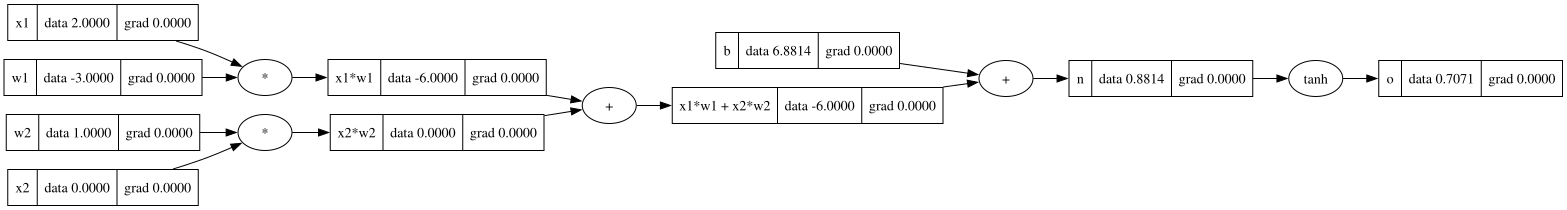

In [126]:
draw_dot(o)

In [127]:
o.backward()

In [128]:
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')
b = Value(6.881373587, label = 'b')
x1w1 = x1*w1; x1w1.label = "x1*w1"
x2w2 = x2*w2; x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = 'n'
e = (2*n).exp()
o = (e -1) / (e+1)

In [129]:
import torch

In [213]:
class Neuron:
    def __init__(self, nin):
        # nin = number of inputs; one weight per input, plus one bias
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w · x + b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range (nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data = 0.4036475294467132)

In [214]:
xs = [
    [2.0,  3.0, -1.0],
    [3.0, -1.0,  0.5],
    [0.5,  1.0,  1.0],
    [1.0,  1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]   # desired targets

In [242]:
for k in range (1000):
    ypred = [n(x) for x in xs]
    loss = sum([(yout-ygt)**2 for ygt, yout in zip(ys, ypred)])

    #backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()
    #update
    for p in n.parameters():
        p.data += -1 * 0.05 * p.grad

    print(k, loss.data)


0 0.0010513816302544013
1 0.001049133664270045
2 0.0010468949510165824
3 0.0010446654343683243
4 0.0010424450586490309
5 0.0010402337686273692
6 0.001038031509512538
7 0.0010358382269498813
8 0.001033653867016605
9 0.0010314783762175059
10 0.0010293117014807355
11 0.001027153790153664
12 0.0010250045899987982
13 0.0010228640491896448
14 0.0010207321163067668
15 0.0010186087403337707
16 0.001016493870653389
17 0.0010143874570436185
18 0.0010122894496738778
19 0.001010199799101228
20 0.0010081184562665967
21 0.0010060453724911322
22 0.001003980499472508
23 0.0010019237892812782
24 0.0009998751943573793
25 0.0009978346675065474
26 0.0009958021618967985
27 0.0009937776310550404
28 0.000991761028863608
29 0.0009897523095569133
30 0.0009877514277180982
31 0.0009857583382757234
32 0.0009837729965005214
33 0.0009817953580021862
34 0.00097982537872613
35 0.0009778630149504066
36 0.0009759082232825219
37 0.000973960960656373
38 0.0009720211843292405
39 0.0009700888518787185
40 0.0009681639211997

In [243]:
ypred

[Value(data = 0.9915590288739028),
 Value(data = -0.9950038552966004),
 Value(data = -0.9868459940185765),
 Value(data = 0.992525863645601)]